# High Multicollinearity Experiment (n >> p)

## 0. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Import data generation
from data_generation.generate_data import generate_data

# Import plots
from plots.coefficient_plot import coefficient_plot
from plots.metrics import compute_metrics

# Import models
from models.OLS import run_ols
from models.LASSO import run_lasso, run_lasso_cv
from models.Ridge import run_ridge, run_ridge_cv
from models.ElasticNet import run_elasticnet_alpha, run_elasticnet_l1ratio, run_elasticnet_cv

# Removing Warnings
import warnings


In [2]:
warnings.filterwarnings('ignore')

## 1. Generating Data

GENERATED DATA:
Shape of X: (150, 50)

X Matrix: 
 [[ 0.03327355  0.01925851  0.0141258  ...  0.02813789  0.06159813
   0.0237842 ]
 [-0.00772527  0.00283325 -0.00417021 ... -0.0016433  -0.0216445
   0.00052462]
 [ 0.05062152  0.05081614  0.01933905 ... -0.03146187  0.01682258
   0.01739924]
 ...
 [ 0.00383903  0.03185723  0.00313237 ... -0.01245602 -0.01708507
  -0.04270372]
 [-0.00738516 -0.03224646  0.00575238 ...  0.00688024 -0.00031456
  -0.00685832]
 [-0.03056867 -0.04658127 -0.0117965  ... -0.00708484 -0.04076778
   0.04029126]]
Shape of y: (150,)

y Vector: 
 [ 5.01630054e+00  6.40417500e-01  6.86388745e+00  6.36253252e-01
  4.94717763e-01  1.68706520e+00  4.57402998e+00 -3.09602424e-01
 -4.32932068e+00 -1.97835379e+00 -1.93609510e+00 -1.04524684e+00
  2.89734803e+00 -7.27698586e+00  2.34401389e+00  3.56321609e+00
 -2.05989909e+00  4.22908390e+00 -1.36208751e+00 -1.94182869e+00
 -5.40396623e+00 -3.17509674e+00  7.15452401e-03 -1.12290122e+00
 -3.82641911e+00  3.32650126e+00  1.

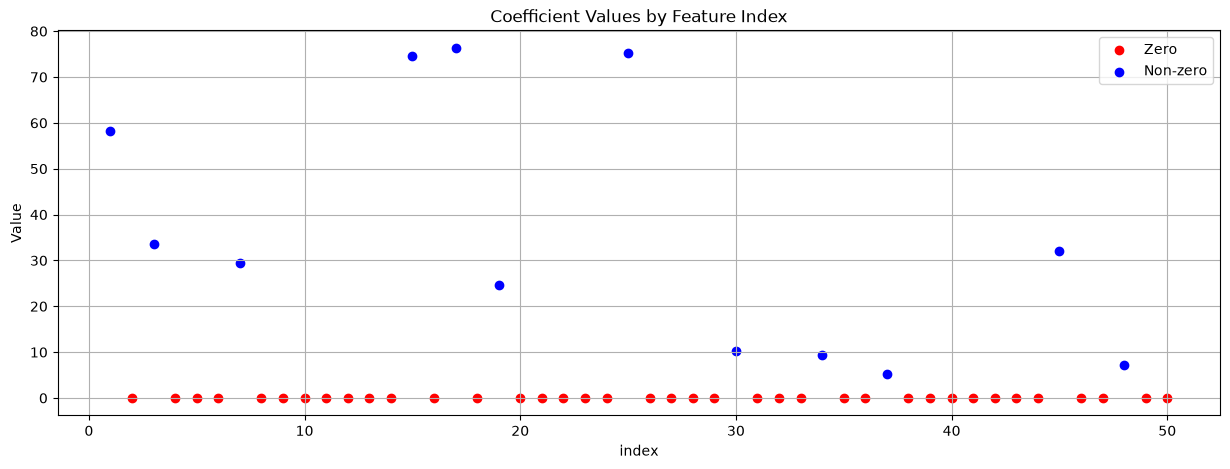

In [ ]:
X_train, X_test, y_train, y_test, coef = generate_data(
    n_samples=150,
    n_features=50,
    n_informative=12,
    noise=0.0,
    effective_rank=5,
    tail_strength=0.1
)

coefficient_plot(coef)


## 2. Ordinary Least Square

MAE: 2.26
MSE: 6.66
RMSE: 2.58
R² Score: 0.23
Number of non zero coefs: 50
Max coef magnitude: 1.9311
Mean coef magnitude: 0.6893


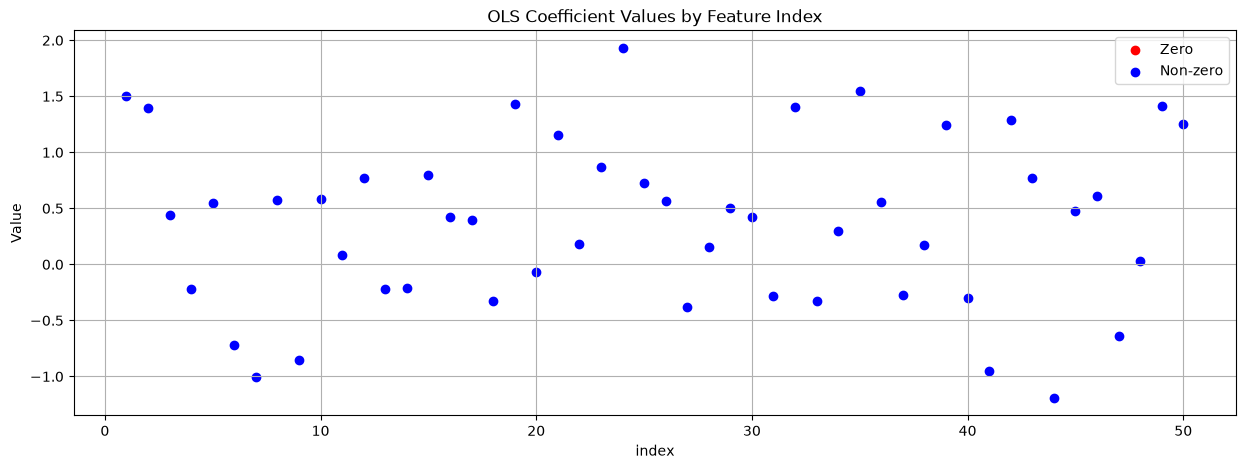

In [4]:
OLS_model = run_ols(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

## 3. Least Absolute Shrinkage and Selection Operator

Metrics for i = 0.001:
MAE: 2.22
MSE: 6.46
RMSE: 2.54
R² Score: 0.25
Number of non zero coefs: 50
Max coef magnitude: 1.8406
Mean coef magnitude: 0.6539


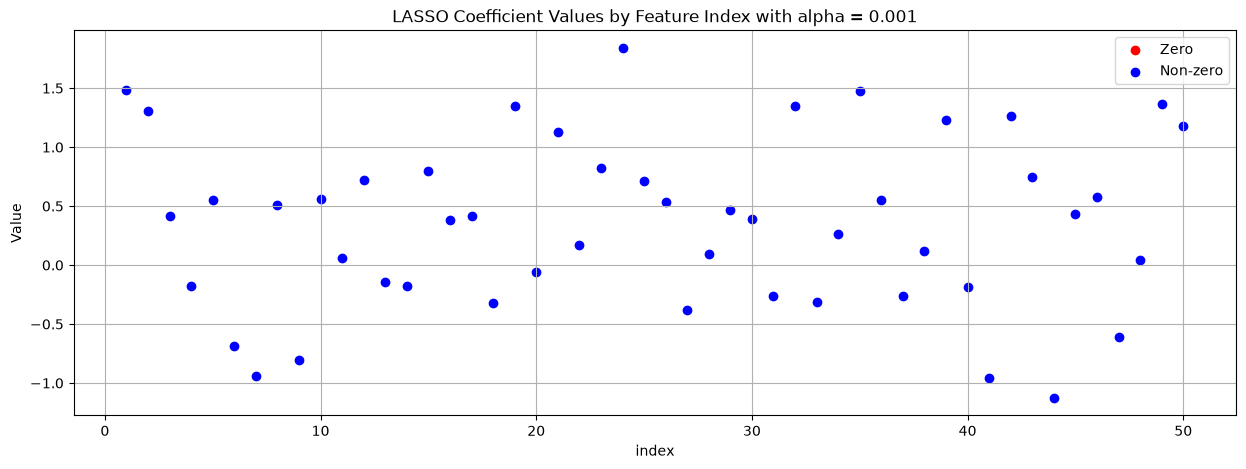

Metrics for i = 0.01:
MAE: 1.95
MSE: 5.14
RMSE: 2.27
R² Score: 0.40
Number of non zero coefs: 42
Max coef magnitude: 1.3116
Mean coef magnitude: 0.4317


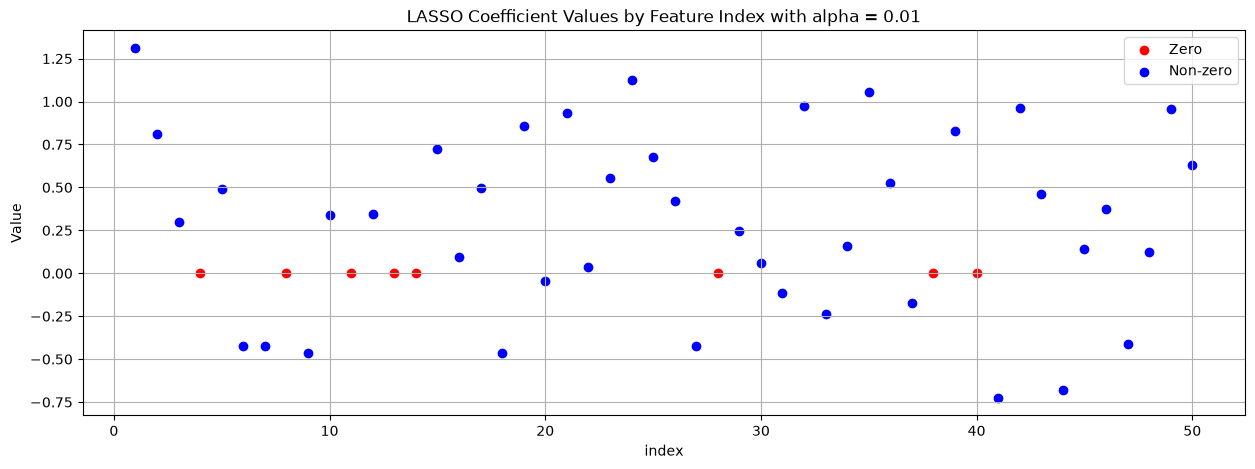

Metrics for i = 0.1:
MAE: 1.70
MSE: 4.54
RMSE: 2.13
R² Score: 0.47
Number of non zero coefs: 9
Max coef magnitude: 1.1717
Mean coef magnitude: 0.0752


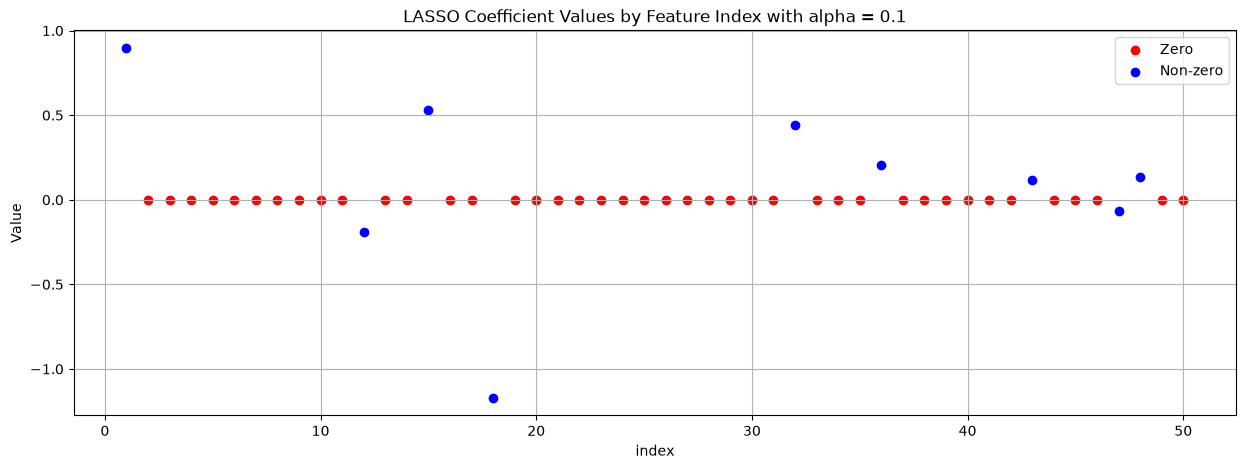

Metrics for i = 1.0:
MAE: 1.94
MSE: 5.46
RMSE: 2.34
R² Score: 0.37
Number of non zero coefs: 4
Max coef magnitude: 0.6797
Mean coef magnitude: 0.0263


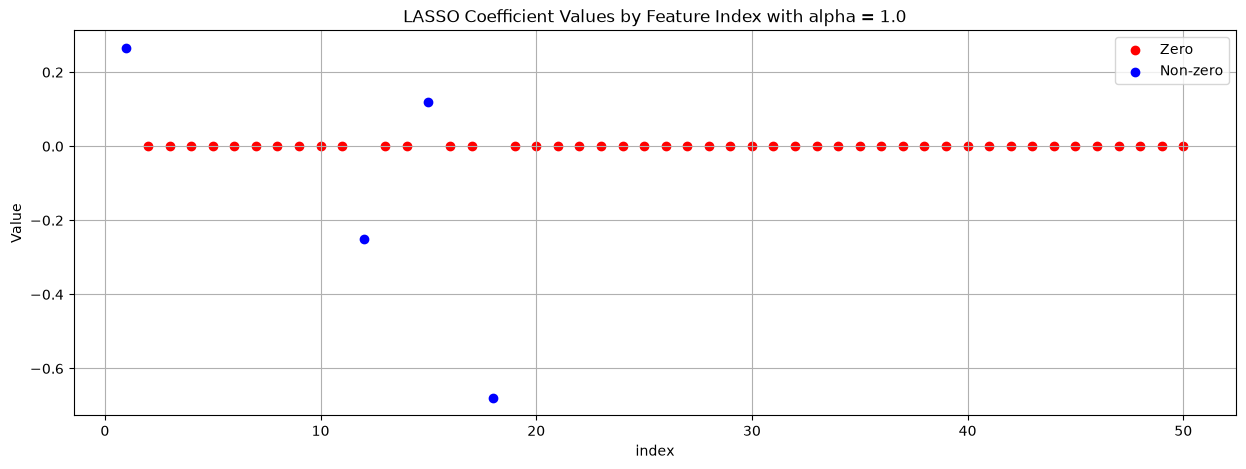

Metrics for i = 10.0:
MAE: 2.45
MSE: 8.79
RMSE: 2.96
R² Score: -0.02
Number of non zero coefs: 0
Max coef magnitude: 0.0000
Mean coef magnitude: 0.0000


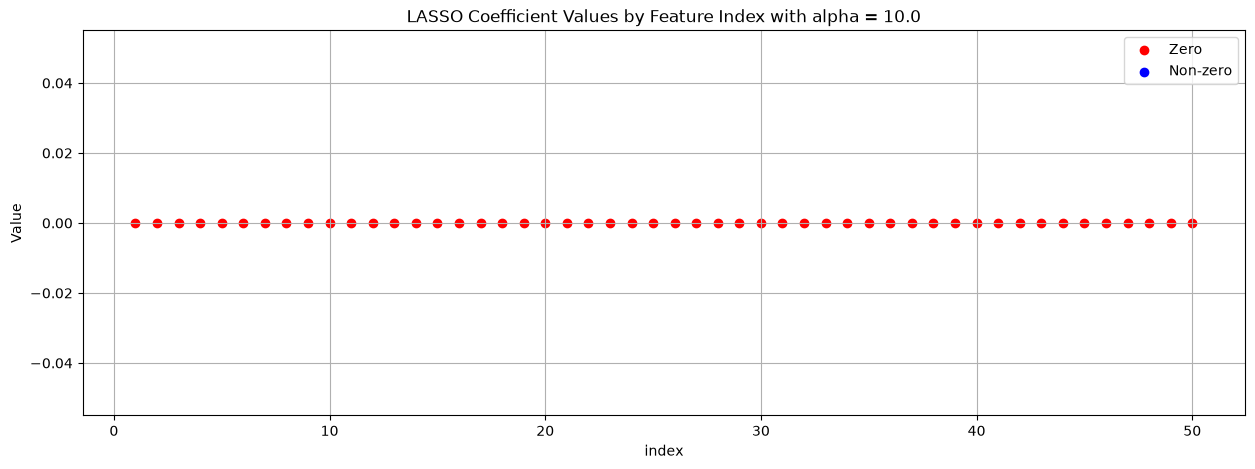

Metrics for i = 100.0:
MAE: 2.45
MSE: 8.79
RMSE: 2.96
R² Score: -0.02
Number of non zero coefs: 0
Max coef magnitude: 0.0000
Mean coef magnitude: 0.0000


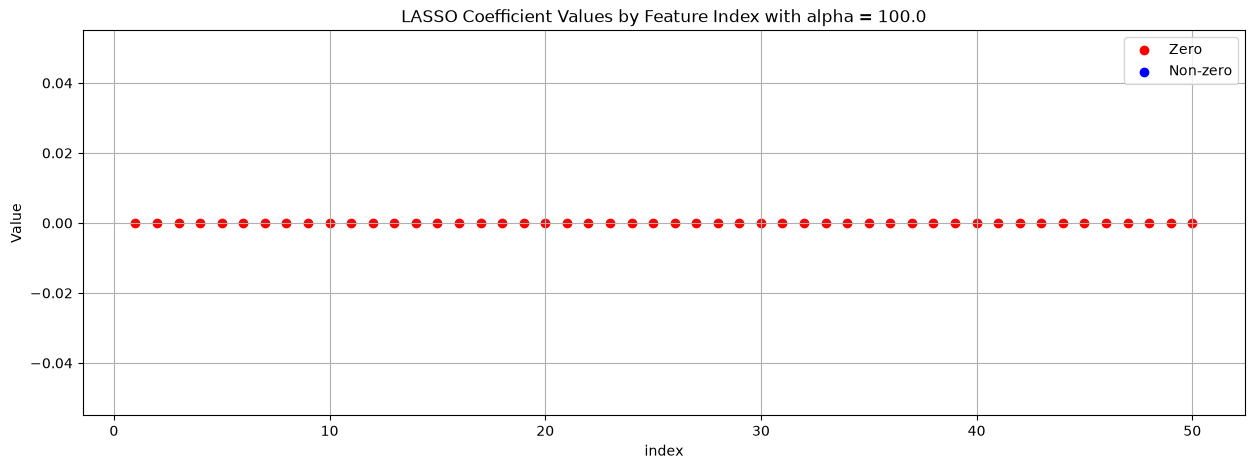

In [5]:
LASSO_models = run_lasso(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

### Best alpha for LASSO

MAE: 1.64
MSE: 4.33
RMSE: 2.08
R² Score: 0.50
Number of non zero coefs: 5
Max coef magnitude: 1.1839
Mean coef magnitude: 0.0588


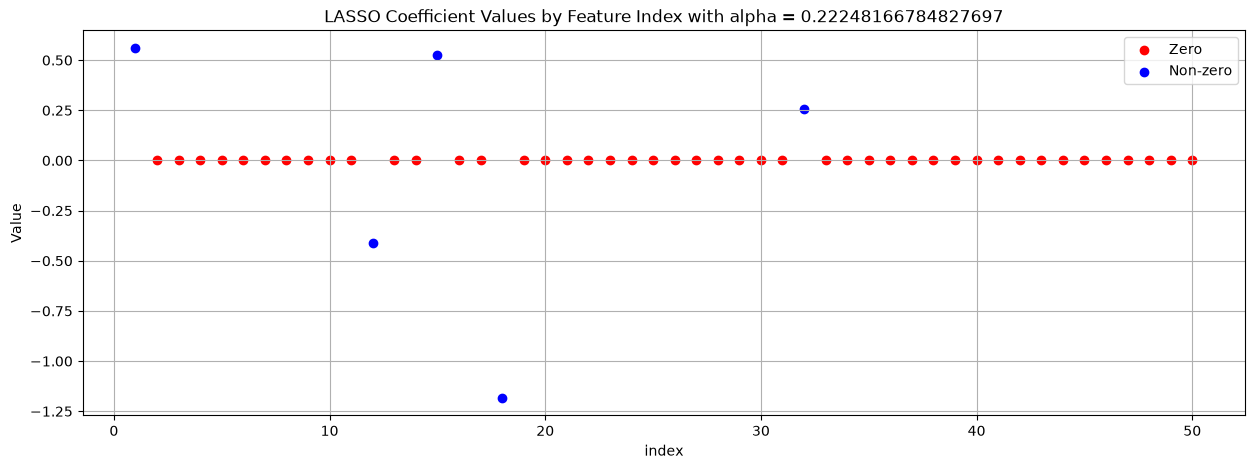

In [6]:
LASSOCV_model = run_lasso_cv(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

## 4. Ridge

Metrics for i = 0.001:
MAE: 2.26
MSE: 6.66
RMSE: 2.58
R² Score: 0.23
Number of non zero coefs: 50
Max coef magnitude: 1.9299
Mean coef magnitude: 0.6891


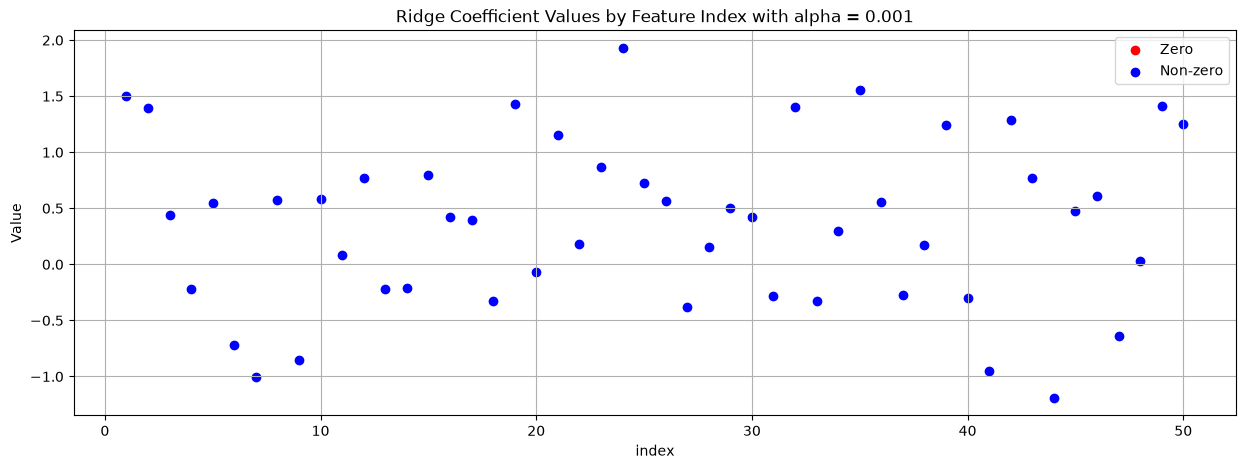

Metrics for i = 0.01:
MAE: 2.26
MSE: 6.64
RMSE: 2.58
R² Score: 0.23
Number of non zero coefs: 50
Max coef magnitude: 1.9190
Mean coef magnitude: 0.6869


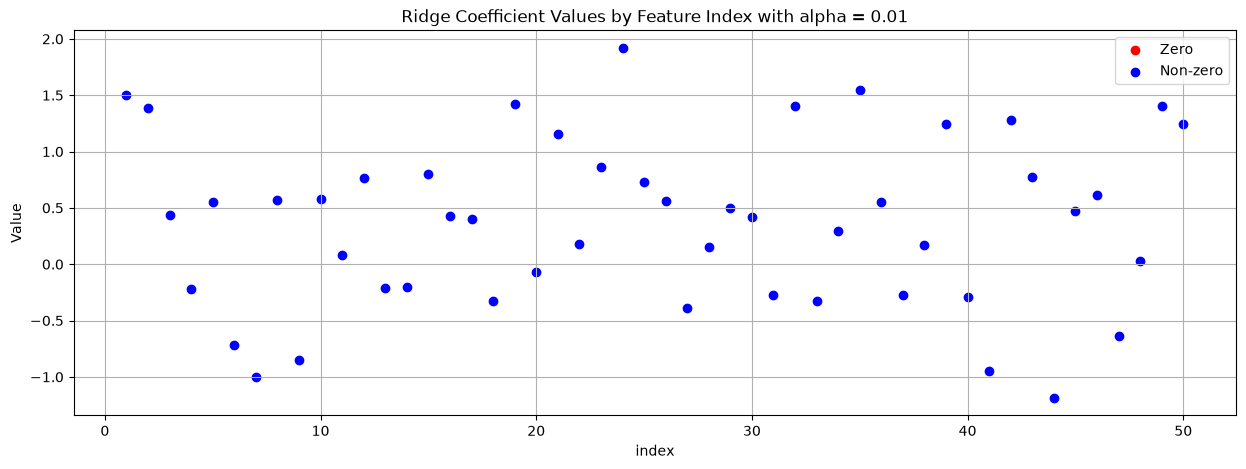

Metrics for i = 0.1:
MAE: 2.23
MSE: 6.49
RMSE: 2.55
R² Score: 0.25
Number of non zero coefs: 50
Max coef magnitude: 1.8176
Mean coef magnitude: 0.6658


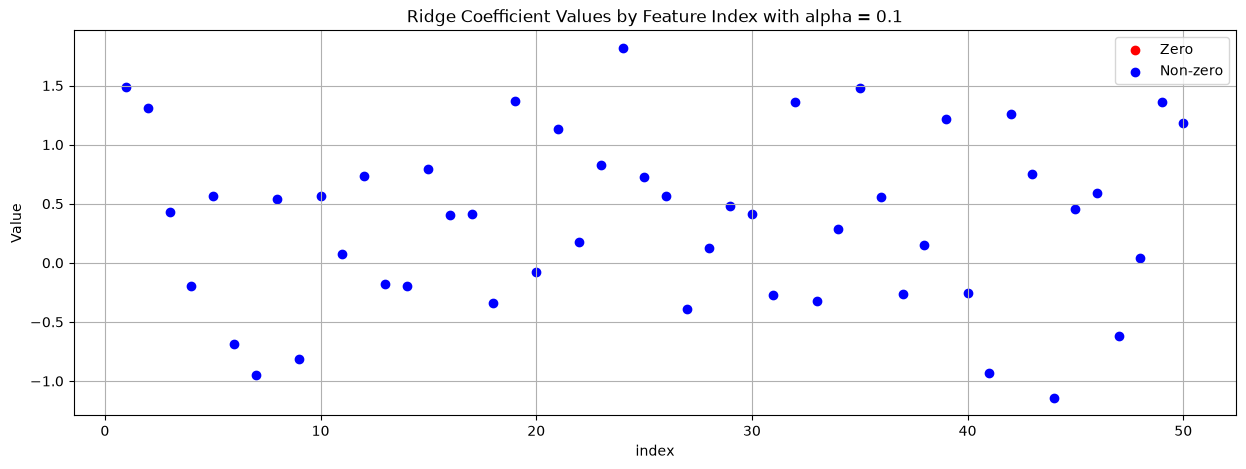

Metrics for i = 1.0:
MAE: 2.05
MSE: 5.58
RMSE: 2.36
R² Score: 0.35
Number of non zero coefs: 50
Max coef magnitude: 1.3358
Mean coef magnitude: 0.5230


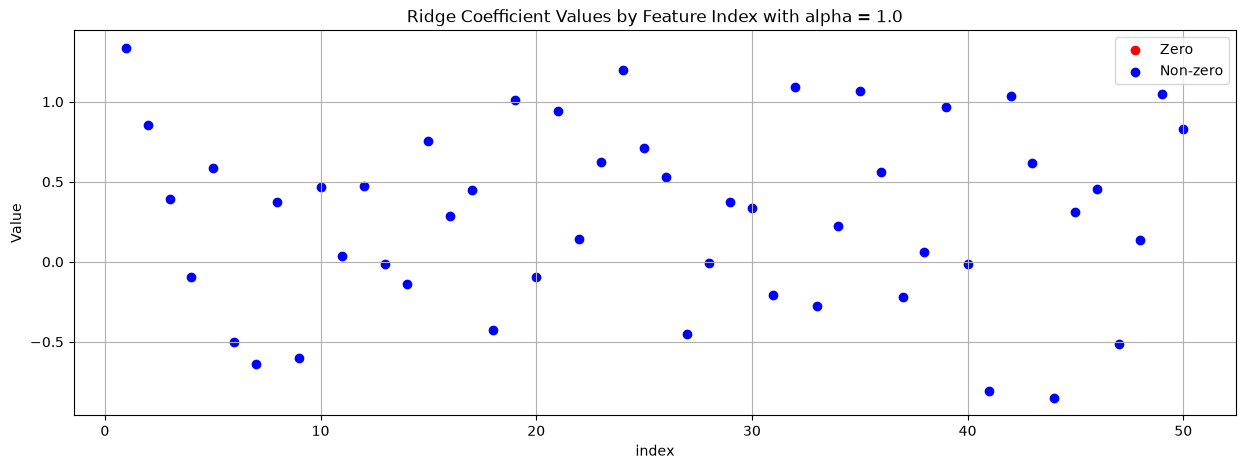

Metrics for i = 10.0:
MAE: 1.79
MSE: 4.62
RMSE: 2.15
R² Score: 0.46
Number of non zero coefs: 50
Max coef magnitude: 0.7116
Mean coef magnitude: 0.2352


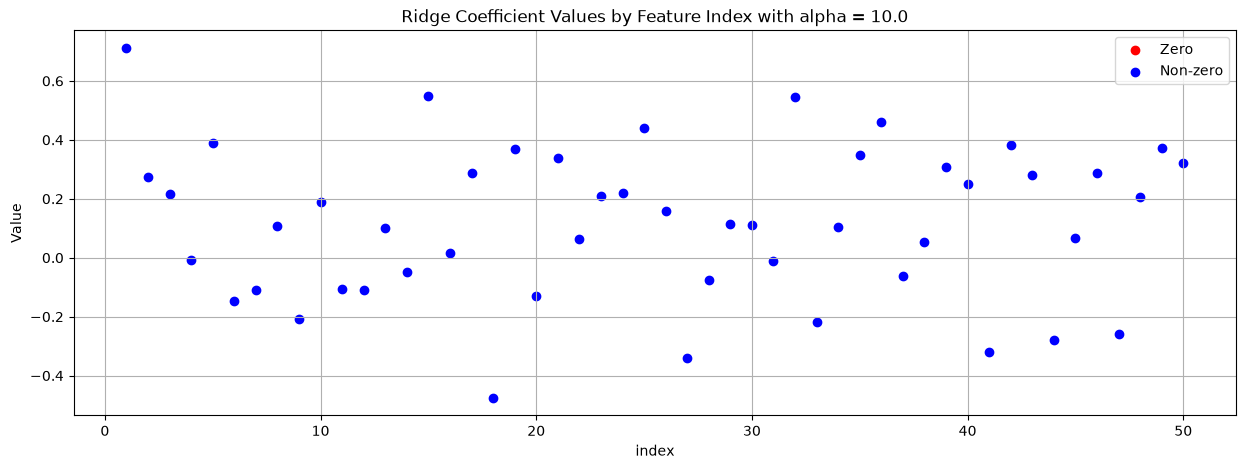

Metrics for i = 100.0:
MAE: 1.74
MSE: 4.61
RMSE: 2.15
R² Score: 0.46
Number of non zero coefs: 50
Max coef magnitude: 0.2932
Mean coef magnitude: 0.0975


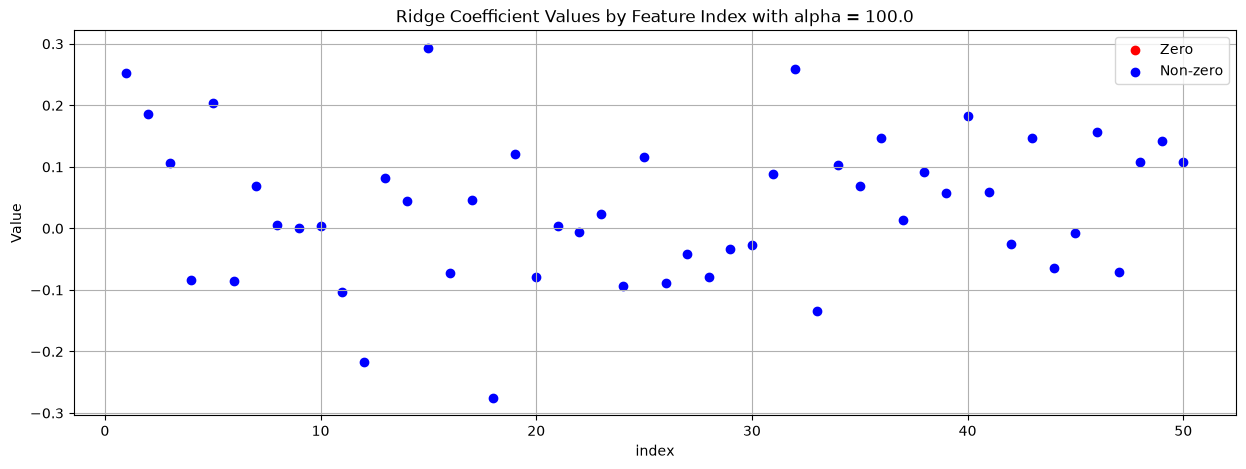

In [7]:
Ridge_models = run_ridge(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

### Ridge Best Alpha

MAE: 1.79
MSE: 4.62
RMSE: 2.15
R² Score: 0.46
Number of non zero coefs: 50
Max coef magnitude: 0.7116
Mean coef magnitude: 0.2352


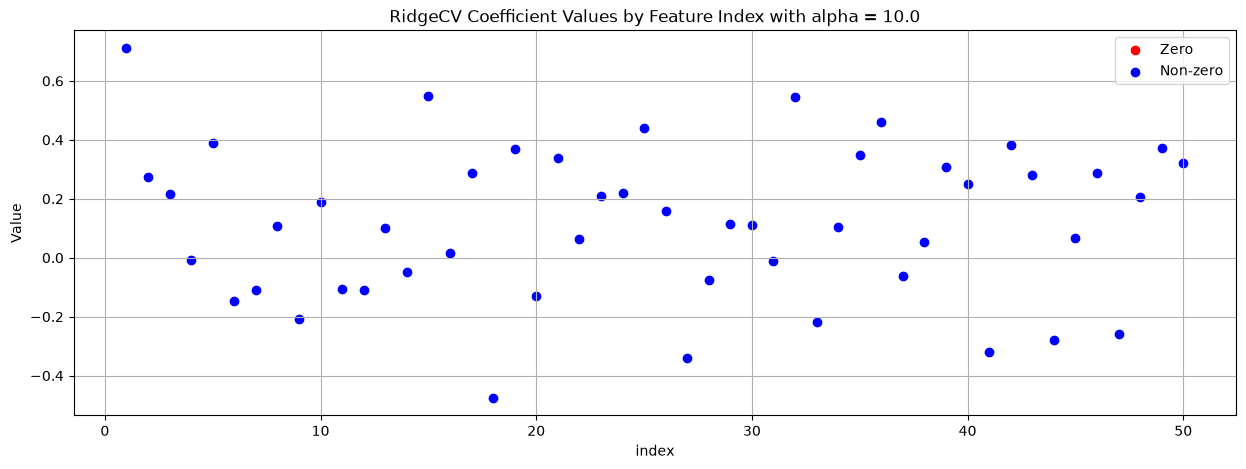

In [8]:
RidgeCV_model = run_ridge_cv(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

## 5. Elastic Net

Metrics for i = 0.001:
MAE: 2.22
MSE: 6.46
RMSE: 2.54
R² Score: 0.25
Number of non zero coefs: 50
Max coef magnitude: 1.8170
Mean coef magnitude: 0.6577


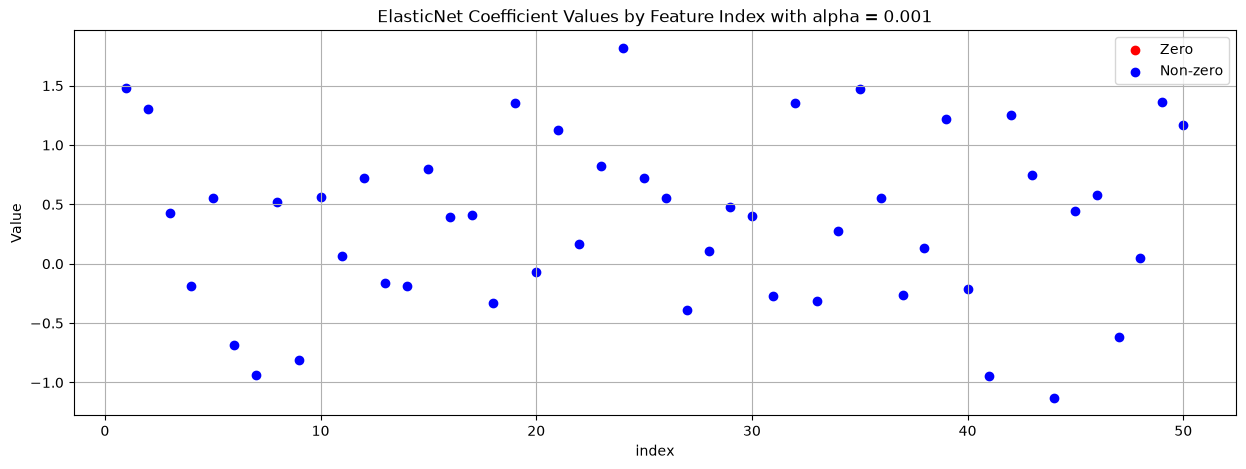

Metrics for i = 0.01:
MAE: 1.99
MSE: 5.32
RMSE: 2.31
R² Score: 0.38
Number of non zero coefs: 46
Max coef magnitude: 1.3084
Mean coef magnitude: 0.4696


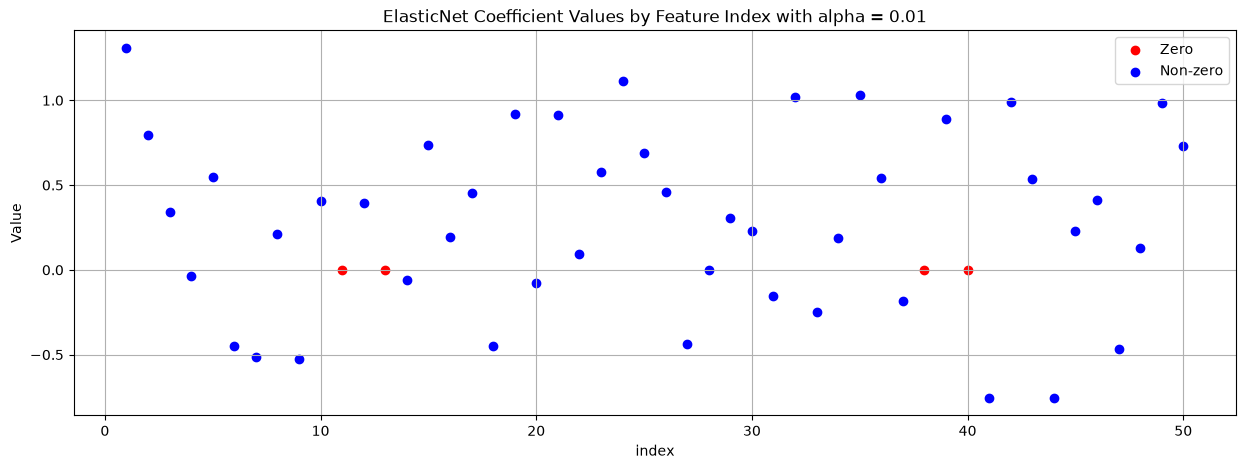

Metrics for i = 0.1:
MAE: 1.70
MSE: 4.37
RMSE: 2.09
R² Score: 0.49
Number of non zero coefs: 22
Max coef magnitude: 0.7232
Mean coef magnitude: 0.0978


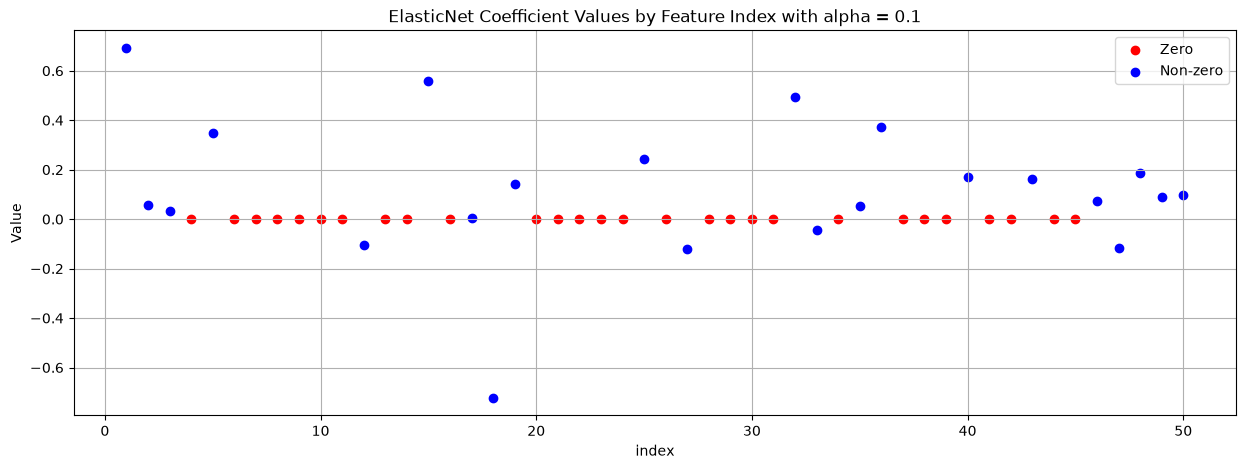

Metrics for i = 1.0:
MAE: 1.77
MSE: 4.51
RMSE: 2.12
R² Score: 0.48
Number of non zero coefs: 11
Max coef magnitude: 0.5380
Mean coef magnitude: 0.0405


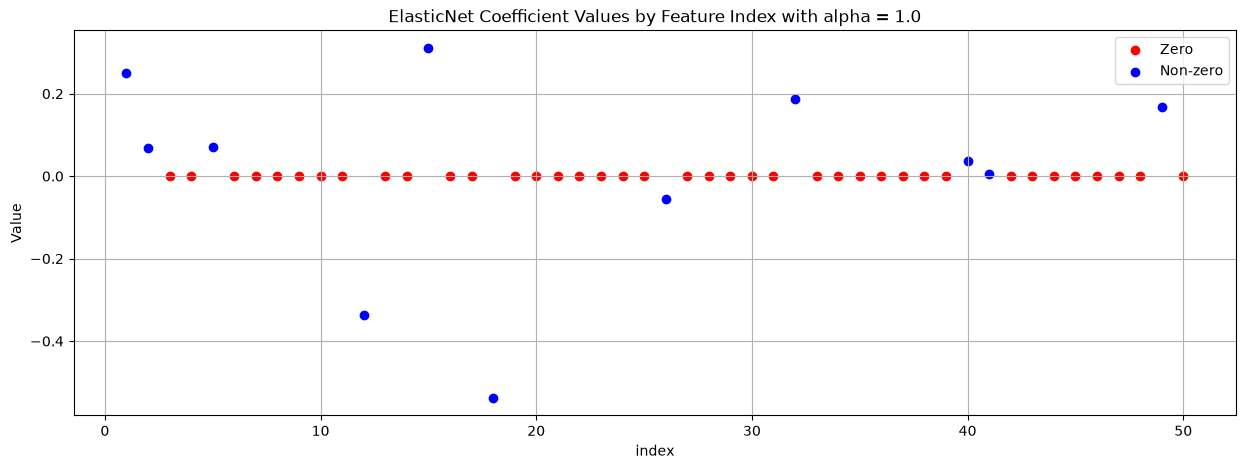

Metrics for i = 10.0:
MAE: 2.45
MSE: 8.79
RMSE: 2.96
R² Score: -0.02
Number of non zero coefs: 0
Max coef magnitude: 0.0000
Mean coef magnitude: 0.0000


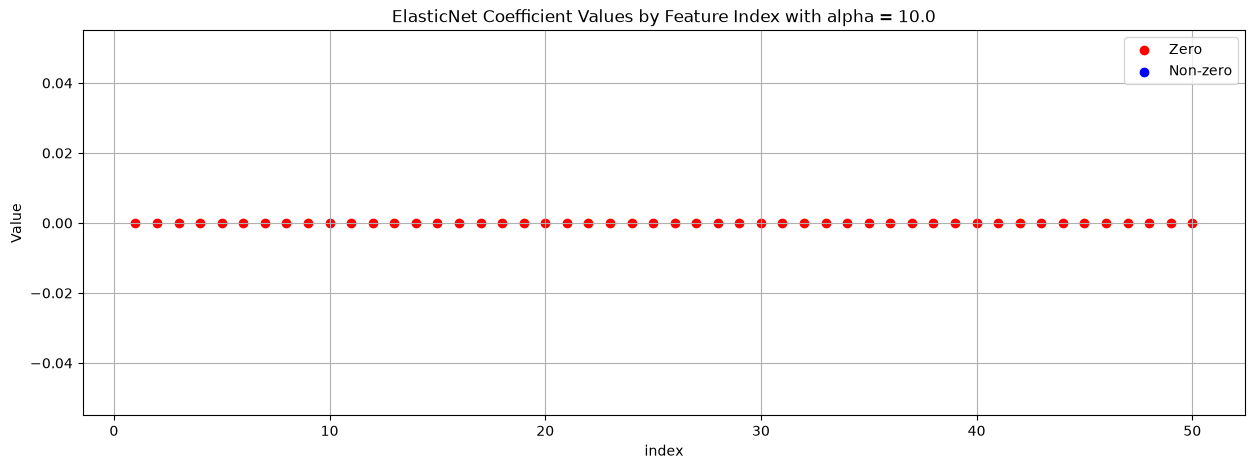

Metrics for i = 100.0:
MAE: 2.45
MSE: 8.79
RMSE: 2.96
R² Score: -0.02
Number of non zero coefs: 0
Max coef magnitude: 0.0000
Mean coef magnitude: 0.0000


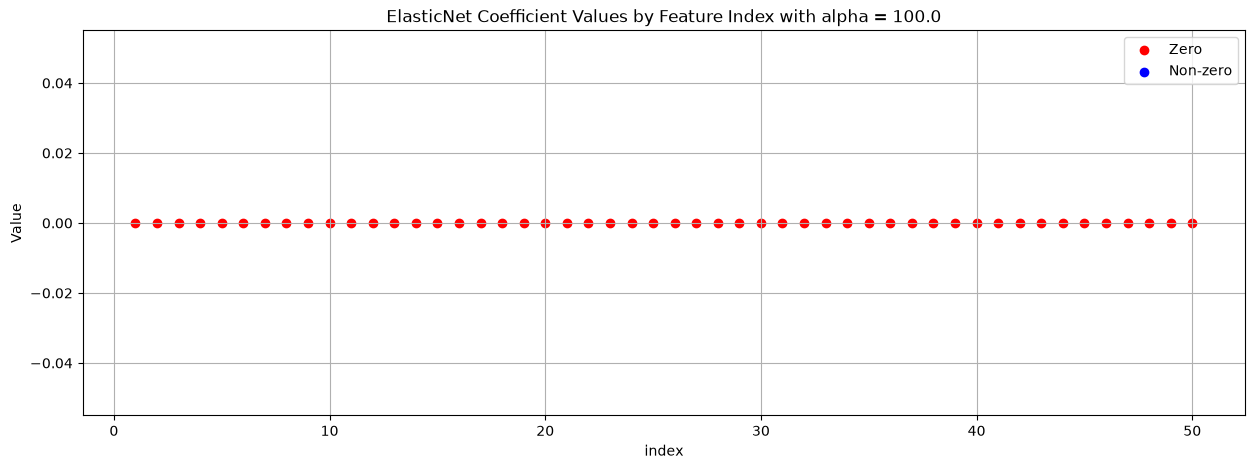

In [9]:
ElasticNet_alpha_models = run_elasticnet_alpha(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

Metrics for i = 0.0:
MAE: 1.74
MSE: 4.59
RMSE: 2.14
R² Score: 0.47
Number of non zero coefs: 50
Max coef magnitude: 0.2761
Mean coef magnitude: 0.0936


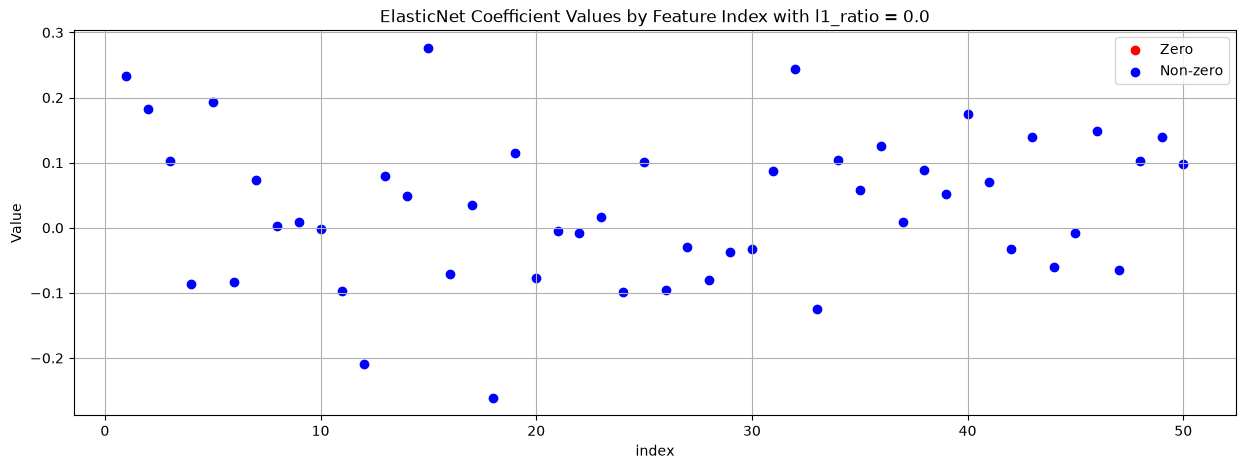

Metrics for i = 0.25:
MAE: 1.71
MSE: 4.37
RMSE: 2.09
R² Score: 0.49
Number of non zero coefs: 23
Max coef magnitude: 0.3773
Mean coef magnitude: 0.0553


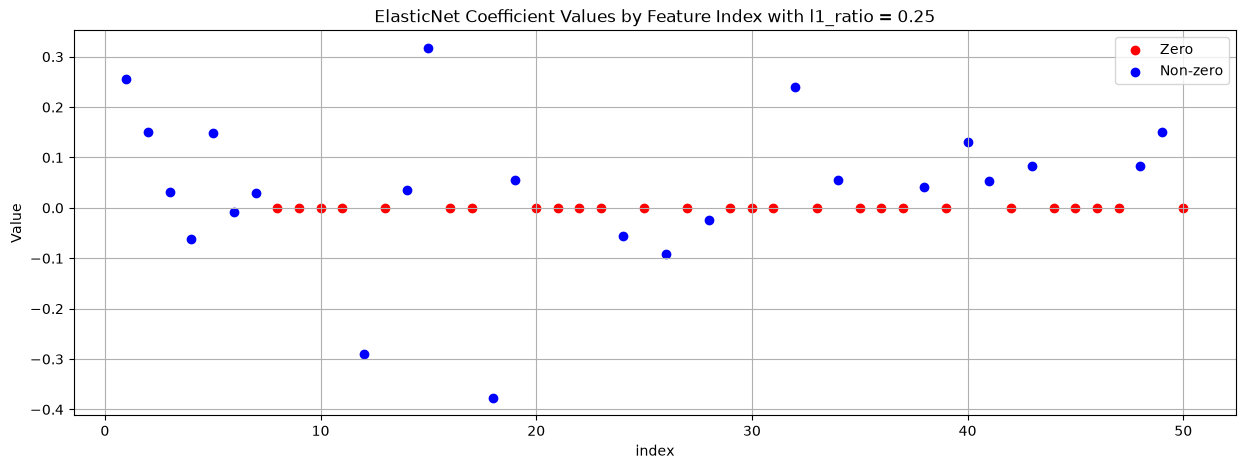

Metrics for i = 0.5:
MAE: 1.77
MSE: 4.51
RMSE: 2.12
R² Score: 0.48
Number of non zero coefs: 11
Max coef magnitude: 0.5380
Mean coef magnitude: 0.0405


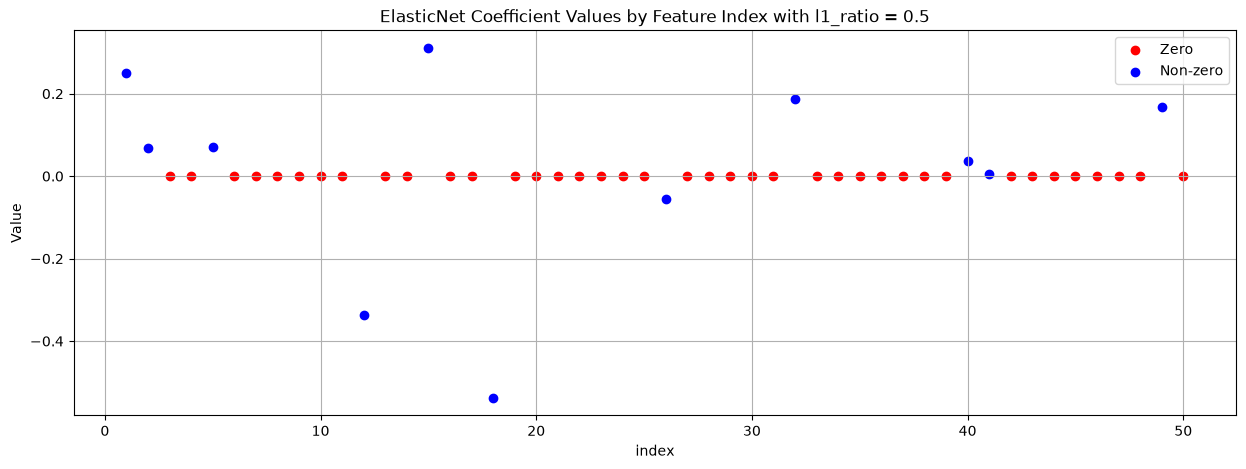

Metrics for i = 0.75:
MAE: 1.83
MSE: 4.84
RMSE: 2.20
R² Score: 0.44
Number of non zero coefs: 6
Max coef magnitude: 0.6251
Mean coef magnitude: 0.0330


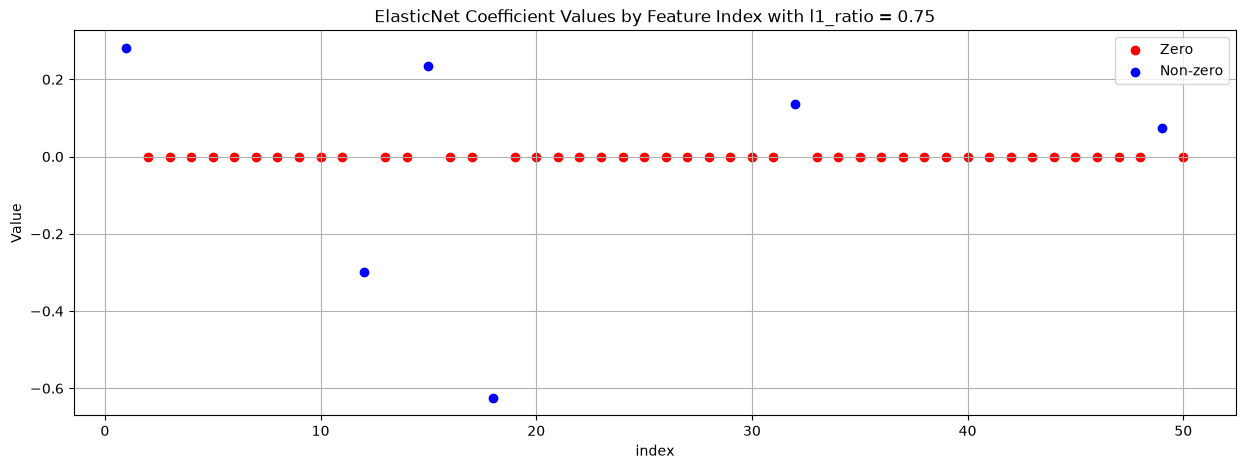

Metrics for i = 1.0:
MAE: 1.94
MSE: 5.46
RMSE: 2.34
R² Score: 0.37
Number of non zero coefs: 4
Max coef magnitude: 0.6797
Mean coef magnitude: 0.0263


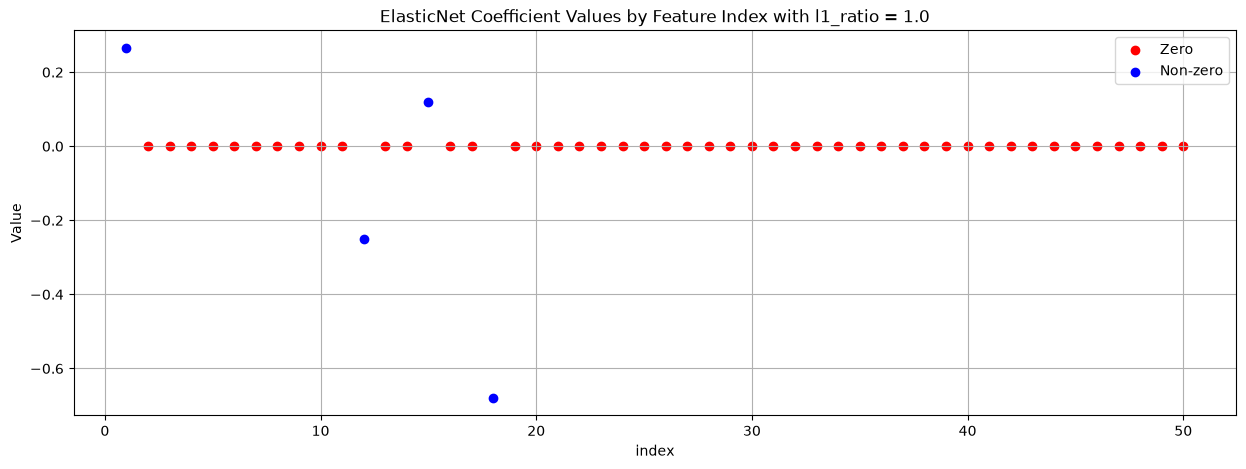

In [10]:
ElasticNet_l1_models = run_elasticnet_l1ratio(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)

### Best alpha and l1 ratio for ElasticNet

MAE: 1.64
MSE: 4.33
RMSE: 2.08
R² Score: 0.50
Number of non zero coefs: 5
Max coef magnitude: 1.1839
Mean coef magnitude: 0.0588


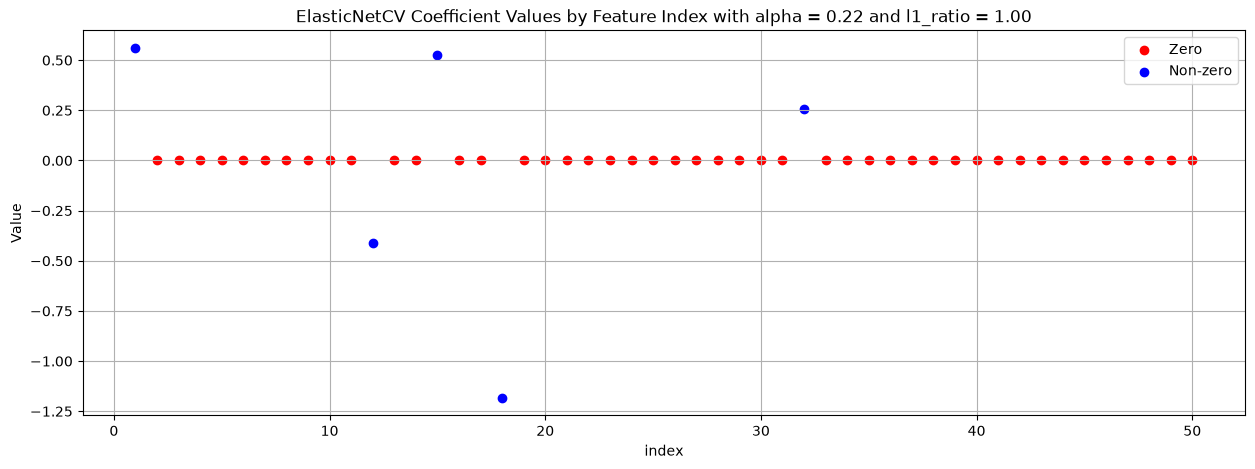

In [11]:
ElasticNet_model = run_elasticnet_cv(X_train, X_test, y_train, y_test, compute_metrics, coefficient_plot)